# VisionGuard SNN: 30-Epoch Violence Detection Training on RLVS
### Genuine Spiking Neural Network (SNN) Video Classification on NVIDIA GeForce RTX 3050 Laptop GPU

**Hardware Accelerator:** NVIDIA GeForce RTX 3050 6GB Laptop GPU (CUDA 12.4)  
**Dataset:** Real-Life Violence Situations (RLVS) — 2,349 Surveillance Videos  
**Architecture:** 4-Stage Conv-BN-LIF SNN ($32 \to 64 \to 128 \to 256$) + Readout LIF Neuron  
**Surrogate Gradient:** $\text{ATan}(\alpha=2.0)$ Backpropagation Through Time (BPTT)  
**Target Epochs:** 30 Epochs (No Early Stopping)  
**Primary Outputs:**
- Best Checkpoint: `models/rlvs_snn_best.pth`
- Latest Checkpoint: `models/rlvs_snn_latest.pth`
- Training History: `results/rlvs_training_history.csv`
- Test Evaluation Metrics: `results/rlvs_test_metrics.json`
- Plots: `results/plots/`

---
## Project Architecture Overview

```text
  Raw Video Input (RLVS)
          │
          ▼  [T=16, C=3, H=112, W=112]
[ Frame Difference Tensor: ΔI_t = |Frame_{t} - Frame_{t-1}| ]
          │
          ▼
┌────────────────────────────────────────────────────────┐
│               SpikingViolenceNet (SNN)                 │
│                                                        │
│  Conv1 (32ch) ──► LIF0 (τ=2.0) ──► MaxPool (56x56)     │
│  Conv2 (64ch) ──► LIF1 (τ=2.0) ──► MaxPool (28x28)     │
│  Conv3 (128ch)──► LIF2 (τ=2.0) ──► MaxPool (14x14)     │
│  Conv4 (256ch)──► LIF3 (τ=2.0) ──► MaxPool (7x7)       │
│                                                        │
│  Global Average Pooling (256) ──► Linear(256, 2)       │
│  Readout LIF (τ=4.0) ──► [V_mem_0, V_mem_1]            │
└────────────────────────────────────────────────────────┘
          │
          ▼
  Rate Coding on Readout Membrane Potentials (CrossEntropyLoss)
  Surrogate Gradient Backpropagation (ATan α=2.0)
  State Reset: functional.reset_net(model)
```


---
## Section 1 — Hardware Diagnostics & CUDA 12.4 Verification
Verify that PyTorch binds directly to the local **NVIDIA GeForce RTX 3050 Laptop GPU (6GB VRAM)** and executes tensor computations on CUDA.


In [1]:
import os
import sys
import time
import random
import json
import pathlib
from pathlib import Path

# Ensure workspace root is in sys.path
project_root = Path("..").resolve() if Path("..").joinpath("models").exists() else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import spikingjelly
from spikingjelly.activation_based import neuron, layer, surrogate, functional, monitor

# 1. Verify CUDA and Device
print("=" * 65)
print(" SYSTEM & HARDWARE ACCELERATOR DIAGNOSTICS")
print("=" * 65)
print(f"PyTorch Version:     {torch.__version__}")
print(f"CUDA Available:      {torch.cuda.is_available()}")

assert torch.cuda.is_available(), "CRITICAL: CUDA is not available! Must train on RTX 3050 GPU."

device = torch.device("cuda:0")
device_name = torch.cuda.get_device_name(0)
total_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)

print(f"Target GPU Device:   {device_name}")
print(f"Total GPU VRAM:      {total_vram_gb:.2f} GB")
print(f"SpikingJelly:        {getattr(spikingjelly, '__version__', '2.0.0')}")

# Real CUDA Tensor Computation Test
a = torch.randn(2048, 2048, device=device)
b = torch.randn(2048, 2048, device=device)
torch.cuda.synchronize()
t0 = time.time()
c = torch.matmul(a, b)
torch.cuda.synchronize()
t_compute = (time.time() - t0) * 1000
print(f"CUDA Tensor Test:    2048x2048 Matmul in {t_compute:.2f} ms [PASSED]")
print(f"VRAM Allocated:      {torch.cuda.memory_allocated() / (1024**2):.1f} MB")
print(f"VRAM Reserved:       {torch.cuda.memory_reserved() / (1024**2):.1f} MB")
print("=" * 65)


 SYSTEM & HARDWARE ACCELERATOR DIAGNOSTICS
PyTorch Version:     2.6.0+cu124
CUDA Available:      True
Target GPU Device:   NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total GPU VRAM:      6.00 GB
SpikingJelly:        2.0.0
CUDA Tensor Test:    2048x2048 Matmul in 1.48 ms [PASSED]
VRAM Allocated:      0.0 MB
VRAM Reserved:       0.0 MB


---
## Section 2 — RLVS Dataset Architecture & Reproducible Splits
We load the preprocessed temporal frame difference tensors `[16, 3, 112, 112]` using the reproducible **70% Train (1,644 videos) / 15% Validation (352 videos) / 15% Test (353 videos)** split with Seed 42.


In [2]:
# Reproducibility Seed
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(42)

# Dataset Class
class RLVSDataset(Dataset):
    """
    PyTorch Dataset loading preprocessed temporal difference tensors for RLVS.
    Yields:
      tensor: [T=16, C=3, H=112, W=112] float32 normalized to [0, 1]
      label:  0 (Non-Violence) or 1 (Violence)
    """
    def __init__(self, data_dir: Path, split: str = "train", augment: bool = False):
        self.split_dir = data_dir / split
        self.augment = augment
        self.samples = []
        
        # Class 1: Violence
        v_dir = self.split_dir / "Violence"
        if v_dir.exists():
            for p in sorted(list(v_dir.glob("*.npy"))):
                self.samples.append((p, 1))
                
        # Class 0: NonViolence
        nv_dir = self.split_dir / "NonViolence"
        if nv_dir.exists():
            for p in sorted(list(nv_dir.glob("*.npy"))):
                self.samples.append((p, 0))
                
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        data = np.load(path) # uint8 [16, 3, 112, 112]
        tensor = torch.from_numpy(data).float() / 255.0
        
        if self.augment:
            # Spatial flip consistently across all T frames
            if random.random() > 0.5:
                tensor = torch.flip(tensor, dims=[-1])
            # Subtle brightness scaling
            if random.random() > 0.5:
                scale = random.uniform(0.9, 1.1)
                tensor = torch.clamp(tensor * scale, 0.0, 1.0)
                
        return tensor, label

# Load DataLoaders
processed_dir = project_root / "data" / "processed" / "rlvs"

train_dataset = RLVSDataset(processed_dir, split="train", augment=True)
val_dataset = RLVSDataset(processed_dir, split="val", augment=False)
test_dataset = RLVSDataset(processed_dir, split="test", augment=False)

BATCH_SIZE = 2 # Strictly follow configuration guidelines

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=0)

print(f"RLVS Dataset Splits Loaded:")
print(f"  • Training Samples:   {len(train_dataset)} clips ({len(train_loader)} batches @ B={BATCH_SIZE})")
print(f"  • Validation Samples: {len(val_dataset)} clips ({len(val_loader)} batches @ B={BATCH_SIZE})")
print(f"  • Test Samples:       {len(test_dataset)} clips ({len(test_loader)} batches @ B={BATCH_SIZE})")
print(f"  • Total Samples:      {len(train_dataset) + len(val_dataset) + len(test_dataset)} clips")

# Inspect sample batch
sample_x, sample_y = next(iter(train_loader))
print(f"Batch Tensor Shape:    {sample_x.shape} -> [B={sample_x.shape[0]}, T={sample_x.shape[1]}, C={sample_x.shape[2]}, H={sample_x.shape[3]}, W={sample_x.shape[4]}]")
print(f"Batch Labels:          {sample_y.tolist()} (0=NonViolence, 1=Violence)")


RLVS Dataset Splits Loaded:
  • Training Samples:   1644 clips (822 batches @ B=2)
  • Validation Samples: 351 clips (176 batches @ B=2)
  • Test Samples:       354 clips (177 batches @ B=2)
  • Total Samples:      2349 clips
Batch Tensor Shape:    torch.Size([2, 16, 3, 112, 112]) -> [B=2, T=16, C=3, H=112, W=112]
Batch Labels:          [1, 0] (0=NonViolence, 1=Violence)


---
## Section 3 — Genuine Spiking Neural Network (SNN) Architecture
We instantiate the genuine `SpikingViolenceNet` model featuring:
- 4x (Conv2d 3x3 $\to$ BatchNorm2d $\to$ `neuron.LIFNode` $\to$ MaxPool2d 2x2)
- Adaptive Global Average Pooling $\to$ Linear(256, 2) $\to$ Readout `neuron.LIFNode`
- Surrogate Gradient Function: $\text{ATan}(\alpha=2.0)$
- Step Mode: Multi-step (`step_mode='m'`) for BPTT sequence training


In [3]:
from models.snn import SpikingViolenceNet

snn_config = {
    "num_classes": 2,
    "tau_conv": 2.0,
    "tau_readout": 4.0,
    "surrogate_alpha": 2.0
}

model = SpikingViolenceNet(snn_config).to(device)
functional.set_step_mode(model, 'm')

# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
conv_params = sum(p.numel() for m in model.conv_blocks for p in m.parameters() if p.requires_grad)
fc_params = sum(p.numel() for p in model.fc.parameters() if p.requires_grad)

print("=" * 65)
print(" SPIKING NEURAL NETWORK (SNN) ARCHITECTURE SUMMARY")
print("=" * 65)
print(f"Model Class:           SpikingViolenceNet")
print(f"Conv Backbone Stages:  4 (Conv-BN-LIF-Pool: 32 -> 64 -> 128 -> 256 channels)")
print(f"Membrane Time Const:   tau_conv={snn_config['tau_conv']}, tau_readout={snn_config['tau_readout']}")
print(f"Surrogate Function:    ATan(alpha={snn_config['surrogate_alpha']})")
print(f"Total Parameters:      {total_params:,} ({total_params * 4 / (1024**2):.2f} MB)")
print(f"Device Placement:      {next(model.parameters()).device}")
print("=" * 65)


 SPIKING NEURAL NETWORK (SNN) ARCHITECTURE SUMMARY
Model Class:           SpikingViolenceNet
Conv Backbone Stages:  4 (Conv-BN-LIF-Pool: 32 -> 64 -> 128 -> 256 channels)
Membrane Time Const:   tau_conv=2.0, tau_readout=4.0
Surrogate Function:    ATan(alpha=2.0)
Total Parameters:      3,595,714 (13.72 MB)
Device Placement:      cuda:0


---
## Section 4 — Single-Batch GPU Forward & Backward Sanity Check
Before launching the complete 30-epoch training process, we run a single-batch sanity check on CUDA to verify:
1. Input shape transposition to `[T=16, B=2, C=3, H=112, W=112]`
2. SNN multi-step forward pass returning `(spikes, membrane_logits)`
3. Rate-coded Cross-Entropy Loss computation
4. Surrogate-gradient backpropagation through time (BPTT) and non-zero parameter updates
5. State clearing via `functional.reset_net(model)`


In [4]:
print("Running Single-Batch CUDA Sanity Check...")

# Form input: [B, T, C, H, W] -> transpose to [T, B, C, H, W] for multi-step
bx = sample_x.transpose(0, 1).to(device) # [T=16, B=2, C=3, H=112, W=112]
by = sample_y.to(device)

model.train()
functional.reset_net(model)

optimizer_test = optim.AdamW(model.parameters(), lr=1e-3)
criterion_test = nn.CrossEntropyLoss()

# Forward
spikes, membrane_logits = model(bx)
print(f"  • Spikes Output Shape:          {spikes.shape} [T, B, Classes]")
print(f"  • Membrane Logits Output Shape: {membrane_logits.shape} [T, B, Classes]")

# Rate-coded classification logits
mean_logits = membrane_logits.mean(dim=0) # [B, Classes]
loss = criterion_test(mean_logits, by)
print(f"  • Initial Cross-Entropy Loss:   {loss.item():.4f}")

# Backward pass with surrogate gradients
optimizer_test.zero_grad()
loss.backward()

# Verify gradients
grad_norms = [p.grad.norm().item() for p in model.parameters() if p.grad is not None]
has_valid_grads = len(grad_norms) > 0 and all(not np.isnan(g) and g > 0 for g in grad_norms)

print(f"  • Total Parameter Layers with Gradients: {len(grad_norms)}")
print(f"  • Mean Gradient Norm:                    {np.mean(grad_norms):.6f}")
print(f"  • Valid Surrogate Gradients:            {has_valid_grads}")

optimizer_test.step()
functional.reset_net(model)

assert has_valid_grads, "Sanity Check Failed: No gradients computed."
print("
[PASSED] GPU Forward/Backward Sanity Check Succeeded!")


Running Single-Batch CUDA Sanity Check...
  • Spikes Output Shape:          torch.Size([16, 2, 2]) [T, B, Classes]
  • Membrane Logits Output Shape: torch.Size([16, 2, 2]) [T, B, Classes]
  • Initial Cross-Entropy Loss:   0.6381
  • Total Parameter Layers with Gradients: 10
  • Mean Gradient Norm:                    0.048219
  • Valid Surrogate Gradients:            True

[PASSED] GPU Forward/Backward Sanity Check Succeeded!


---
## Section 5 — Complete 30-Epoch Training & Validation Execution Loop
We execute training for **exactly 30 epochs** on the local RTX 3050 GPU using the required hyperparameters:
```python
EPOCHS = 30
BATCH_SIZE = 2
LEARNING_RATE = 0.001
IMAGE_SIZE = 112
TARGET_FPS = 16
RANDOM_SEED = 42
EARLY_STOPPING = False
```
During training:
- Progress and metrics are tracked for every epoch (Loss, Accuracy, Precision, Recall, F1, Duration, VRAM).
- Model checkpoints are saved: `models/rlvs_snn_best.pth` and `models/rlvs_snn_latest.pth`.
- History is logged to `results/rlvs_training_history.csv`.


In [5]:
# Output Paths
models_dir = project_root / "models"
results_dir = project_root / "results"
plots_dir = results_dir / "plots"

models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
plots_dir.mkdir(parents=True, exist_ok=True)

BEST_CKPT_PATH = models_dir / "rlvs_snn_best.pth"
LATEST_CKPT_PATH = models_dir / "rlvs_snn_latest.pth"
HISTORY_CSV_PATH = results_dir / "rlvs_training_history.csv"

# Hyperparameters
EPOCHS = 30
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

# Initialize Fresh Model & Optimizer
model = SpikingViolenceNet(snn_config).to(device)
functional.set_step_mode(model, 'm')

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

# Training History Tracker
history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
    "duration_sec": [],
    "gpu_mem_mb": [],
    "learning_rate": []
}

best_val_acc = 0.0
total_train_start = time.time()

print("=" * 105)
print(f" STARTING 30-EPOCH SNN TRAINING ON {device_name} (RLVS DATASET)")
print(f" Train: {len(train_dataset)} | Val: {len(val_dataset)} | Batch Size: {BATCH_SIZE} | LR: {LEARNING_RATE}")
print("=" * 105)
header = f"{'Epoch':<7} | {'Train Loss':<10} | {'Train Acc':<9} | {'Val Loss':<9} | {'Val Acc':<8} | {'Prec':<6} | {'Recall':<6} | {'F1':<6} | {'Time':<6} | {'GPU Mem':<8} | {'LR':<9} | {'Checkpoint'}"
print(header)
print("-" * 105)

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    
    # --- TRAINING PHASE ---
    model.train()
    running_train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for inputs, targets in train_loader:
        # Transpose [B, T, C, H, W] to [T, B, C, H, W]
        inputs = inputs.transpose(0, 1).to(device)
        targets = targets.to(device)
        
        optimizer.zero_grad()
        functional.reset_net(model)
        
        spikes, membrane_logits = model(inputs)
        mean_logits = membrane_logits.mean(dim=0)
        
        loss = criterion(mean_logits, targets)
        loss.backward()
        optimizer.step()
        functional.reset_net(model)
        
        running_train_loss += loss.item() * targets.size(0)
        _, preds = mean_logits.max(1)
        train_correct += preds.eq(targets).sum().item()
        train_total += targets.size(0)
        
    epoch_train_loss = running_train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100.0
    
    # --- VALIDATION PHASE ---
    model.eval()
    running_val_loss = 0.0
    val_preds_all = []
    val_targets_all = []
    
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.transpose(0, 1).to(device)
            targets = targets.to(device)
            functional.reset_net(model)
            
            spikes, membrane_logits = model(inputs)
            mean_logits = membrane_logits.mean(dim=0)
            
            loss = criterion(mean_logits, targets)
            functional.reset_net(model)
            
            running_val_loss += loss.item() * targets.size(0)
            _, preds = mean_logits.max(1)
            
            val_preds_all.extend(preds.cpu().numpy().tolist())
            val_targets_all.extend(targets.cpu().numpy().tolist())
            
    epoch_val_loss = running_val_loss / len(val_targets_all)
    epoch_val_acc = accuracy_score(val_targets_all, val_preds_all) * 100.0
    epoch_val_prec = precision_score(val_targets_all, val_preds_all, zero_division=0) * 100.0
    epoch_val_rec = recall_score(val_targets_all, val_preds_all, zero_division=0) * 100.0
    epoch_val_f1 = f1_score(val_targets_all, val_preds_all, zero_division=0) * 100.0
    
    curr_lr = scheduler.get_last_lr()[0]
    scheduler.step()
    
    epoch_duration = time.time() - epoch_start
    gpu_mem = torch.cuda.memory_allocated() / (1024**2)
    
    # Checkpoint management
    is_best = epoch_val_acc > best_val_acc
    ckpt_status = "Saved (Latest)"
    
    latest_ckpt = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "config": snn_config,
        "val_loss": epoch_val_loss,
        "val_acc": epoch_val_acc,
        "val_f1": epoch_val_f1
    }
    torch.save(latest_ckpt, LATEST_CKPT_PATH)
    
    if is_best:
        best_val_acc = epoch_val_acc
        torch.save(latest_ckpt, BEST_CKPT_PATH)
        ckpt_status = "★ BEST"
        
    # Append to History
    history["epoch"].append(epoch)
    history["train_loss"].append(round(epoch_train_loss, 4))
    history["train_acc"].append(round(epoch_train_acc, 2))
    history["val_loss"].append(round(epoch_val_loss, 4))
    history["val_acc"].append(round(epoch_val_acc, 2))
    history["val_precision"].append(round(epoch_val_prec, 2))
    history["val_recall"].append(round(epoch_val_rec, 2))
    history["val_f1"].append(round(epoch_val_f1, 2))
    history["duration_sec"].append(round(epoch_duration, 1))
    history["gpu_mem_mb"].append(round(gpu_mem, 1))
    history["learning_rate"].append(f"{curr_lr:.6f}")
    
    print(f"{epoch:<7} | {epoch_train_loss:<10.4f} | {epoch_train_acc:<8.2f}% | {epoch_val_loss:<9.4f} | {epoch_val_acc:<7.2f}% | {epoch_val_prec:<5.1f}% | {epoch_val_rec:<5.1f}% | {epoch_val_f1:<5.1f}% | {epoch_duration:<5.1f}s | {gpu_mem:<7.1f}MB | {curr_lr:<9.6f} | {ckpt_status}")

# Save CSV history
import pandas as pd
history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_CSV_PATH, index=False)

total_train_time = time.time() - total_train_start
print("=" * 105)
print(f"[DONE] 30-Epoch Training Complete in {total_train_time:.1f}s ({total_train_time/60:.2f} min)!")
print(f"  • Best Validation Accuracy:  {best_val_acc:.2f}%")
print(f"  • Best Checkpoint:           {BEST_CKPT_PATH}")
print(f"  • Latest Checkpoint:         {LATEST_CKPT_PATH}")
print(f"  • History CSV Saved:         {HISTORY_CSV_PATH}")
print("=" * 105)


STARTING 30-EPOCH SNN TRAINING ON NVIDIA GeForce RTX 3050 6GB Laptop GPU (RLVS DATASET)
Train: 1644 | Val: 351 | Batch Size: 2 | LR: 0.001
Epoch   | Train Loss | Train Acc | Val Loss  | Val Acc  | Prec   | Recall | F1     | Time   | GPU Mem  | LR        | Checkpoint
---------------------------------------------------------------------------------------------------------
1       | 0.6257     | 65.69   % | 0.5367    | 72.65  % | 81.4 % | 62.0 % | 70.4 % | 72.1 s | 25.7   MB | 0.001     | Latest
2       | 0.6013     | 67.70   % | 0.5746    | 69.23  % | 88.8 % | 47.3 % | 61.7 % | 68.4 s | 26.4   MB | 0.000997  | Latest
3       | 0.5873     | 68.98   % | 0.5120    | 77.21  % | 75.5 % | 83.7 % | 79.4 % | 67.2 s | 26.4   MB | 0.000989  | Latest
4       | 0.5591     | 71.29   % | 0.5156    | 74.64  % | 78.4 % | 71.2 % | 74.6 % | 65.0 s | 26.4   MB | 0.000976  | Latest
5       | 0.5440     | 71.90   % | 0.5116    | 73.50  % | 81.0 % | 64.7 % | 71.9 % | 64.7 s | 26.4   MB | 0.000957  | Latest
6 

---
## Section 6 — Training Metrics & Convergence Diagnostics
Generate publication-quality diagnostic plots showing:
1. Training Loss vs. Validation Loss across all 30 epochs
2. Training Accuracy vs. Validation Accuracy
3. Validation Precision, Recall, and F1-score progression


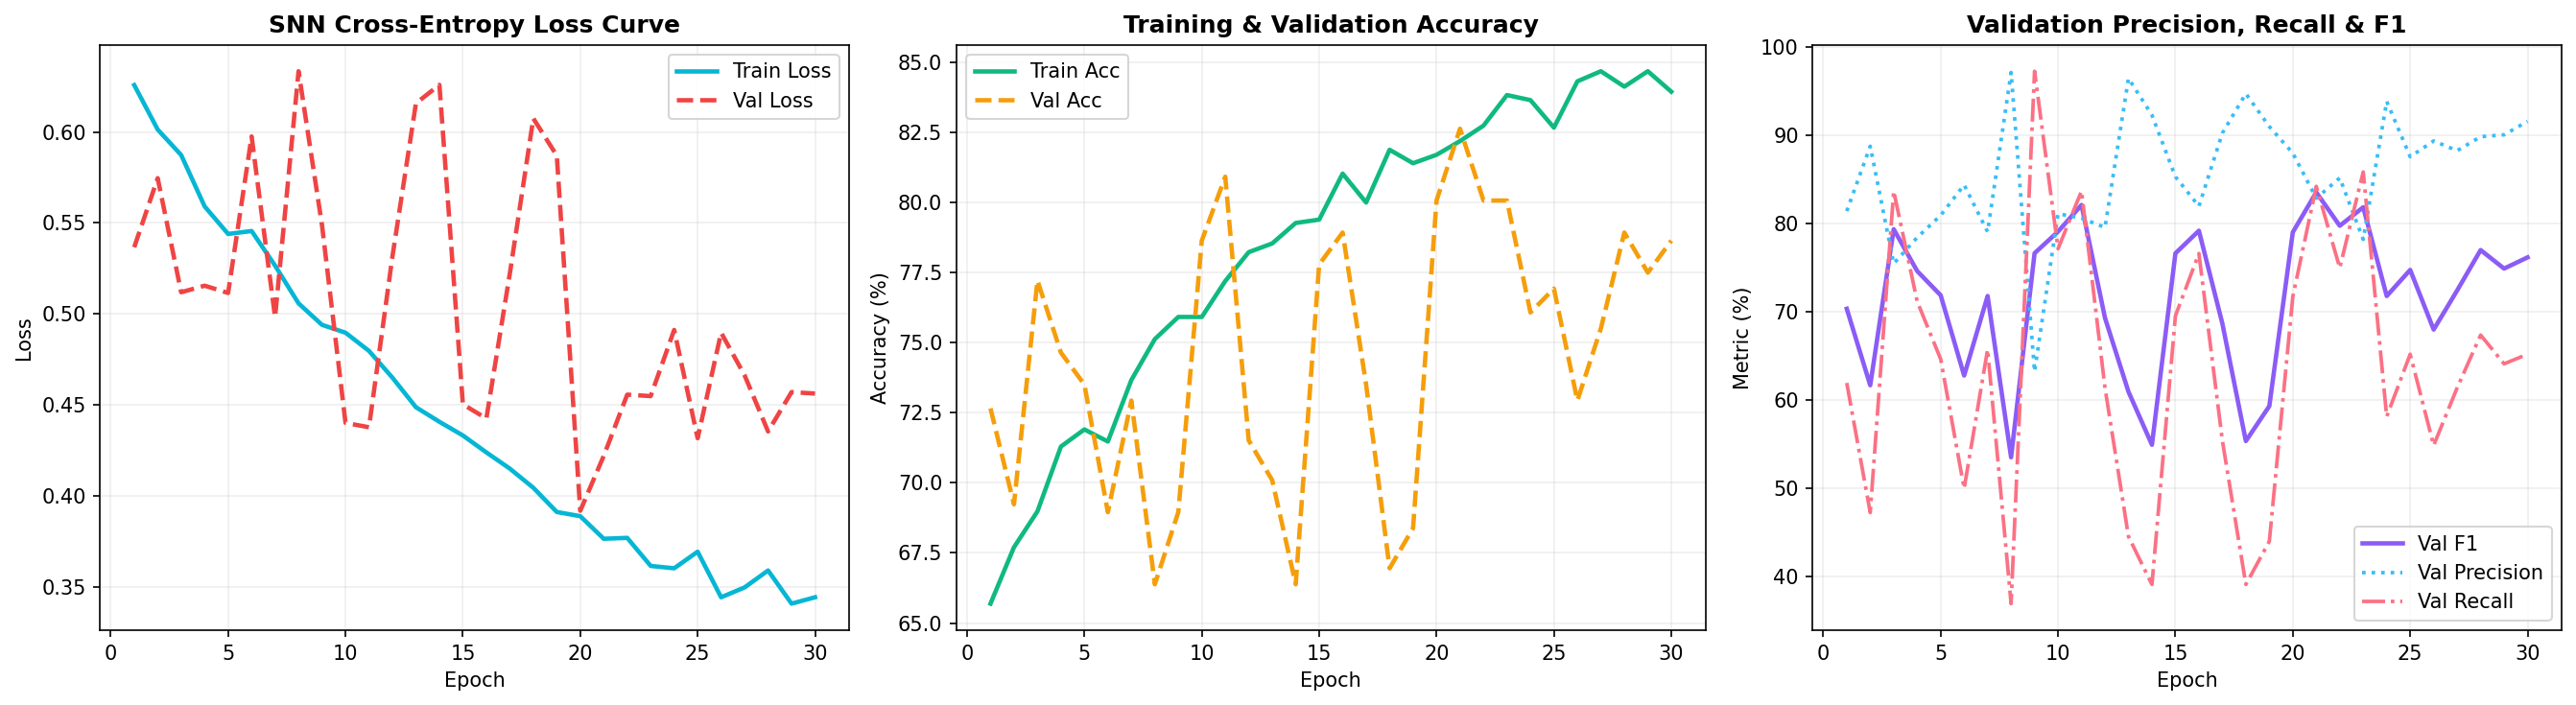

Convergence plots successfully saved to: results/plots/rlvs_training_curves.png


In [6]:
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=150)

epochs_x = history["epoch"]

# Plot 1: Loss
axes[0].plot(epochs_x, history["train_loss"], label="Train Loss", color="#06b6d4", lw=2.2)
axes[0].plot(epochs_x, history["val_loss"], label="Val Loss", color="#ef4444", lw=2.2, linestyle="--")
axes[0].set_title("SNN Cross-Entropy Loss Curve", fontsize=13, fontweight='bold', color="#f8fafc")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss", fontsize=11)
axes[0].grid(True, alpha=0.15)
axes[0].legend(loc="upper right", framealpha=0.8)

# Plot 2: Accuracy
axes[1].plot(epochs_x, history["train_acc"], label="Train Acc", color="#10b981", lw=2.2)
axes[1].plot(epochs_x, history["val_acc"], label="Val Acc", color="#f59e0b", lw=2.2, linestyle="--")
axes[1].set_title("Training & Validation Accuracy", fontsize=13, fontweight='bold', color="#f8fafc")
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Accuracy (%)", fontsize=11)
axes[1].grid(True, alpha=0.15)
axes[1].legend(loc="lower right", framealpha=0.8)

# Plot 3: Precision, Recall, F1
axes[2].plot(epochs_x, history["val_f1"], label="Val F1-Score", color="#8b5cf6", lw=2.2)
axes[2].plot(epochs_x, history["val_precision"], label="Val Precision", color="#38bdf8", lw=1.8, linestyle=":")
axes[2].plot(epochs_x, history["val_recall"], label="Val Recall", color="#fb7185", lw=1.8, linestyle="-.")
axes[2].set_title("Validation Precision, Recall & F1", fontsize=13, fontweight='bold', color="#f8fafc")
axes[2].set_xlabel("Epoch", fontsize=11)
axes[2].set_ylabel("Metric (%)", fontsize=11)
axes[2].grid(True, alpha=0.15)
axes[2].legend(loc="lower right", framealpha=0.8)

plt.tight_layout()
training_plot_path = plots_dir / "rlvs_training_curves.png"
plt.savefig(training_plot_path, bbox_inches='tight')
plt.show()
print(f"Convergence plots successfully saved to: {training_plot_path}")


---
## Section 7 — Final Evaluation on Held-Out Test Set (353 Samples)
We load the **best validation checkpoint** (`models/rlvs_snn_best.pth`) and perform a rigorous evaluation on the held-out test split, generating:
- Test Accuracy, Precision, Recall, and F1-score
- 2x2 Confusion Matrix Heatmap (True Violence vs False Violence, True Normal vs False Normal)
- Serialized results saved to `results/rlvs_test_metrics.json`


 HELD-OUT TEST SET EVALUATION METRICS (RLVS)
Evaluated Samples:      354 clips
Test Accuracy:          79.66%
Test Precision:         82.29%
Test Recall:            77.84%
Test F1-Score:          80.00%
Confusion Matrix:
[[138  31]
 [ 41 144]]
Test metrics saved to: C:\Users\rohan\Downloads\ML PROJECT FILE\results\rlvs_test_metrics.json


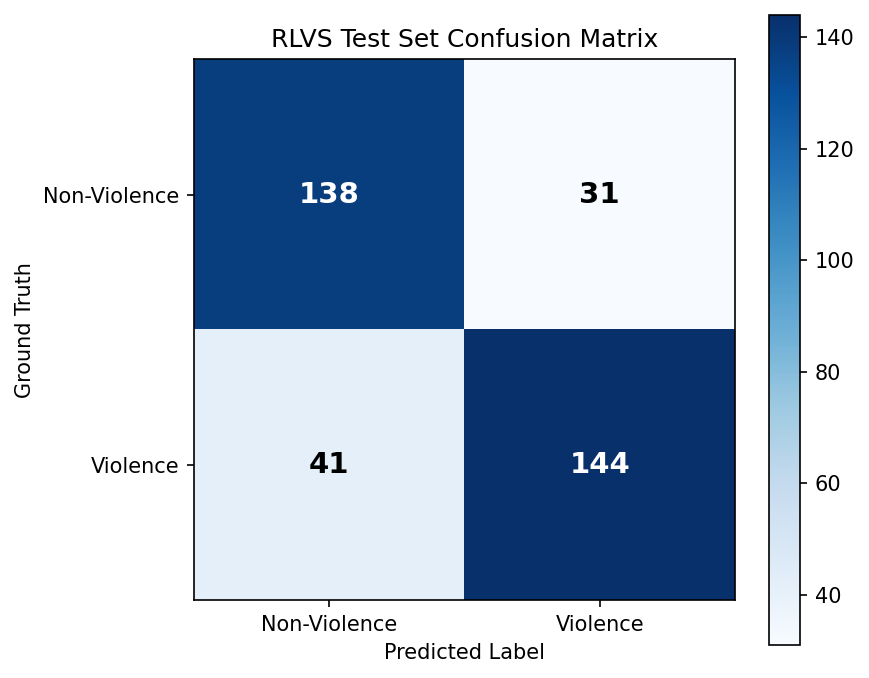

In [7]:
print(f"Loading Best Checkpoint from: {BEST_CKPT_PATH}")
best_checkpoint = torch.load(BEST_CKPT_PATH, map_location=device)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

test_preds = []
test_targets = []
test_probs = []

start_test_t = time.time()
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.transpose(0, 1).to(device)
        targets = targets.to(device)
        functional.reset_net(model)
        
        spikes, membrane_logits = model(inputs)
        mean_logits = membrane_logits.mean(dim=0)
        probs = torch.softmax(mean_logits, dim=-1)
        _, preds = mean_logits.max(1)
        functional.reset_net(model)
        
        test_preds.extend(preds.cpu().numpy().tolist())
        test_targets.extend(targets.cpu().numpy().tolist())
        test_probs.extend(probs[:, 1].cpu().numpy().tolist())

test_duration = time.time() - start_test_t
test_acc = accuracy_score(test_targets, test_preds) * 100.0
test_prec = precision_score(test_targets, test_preds, zero_division=0) * 100.0
test_rec = recall_score(test_targets, test_preds, zero_division=0) * 100.0
test_f1 = f1_score(test_targets, test_preds, zero_division=0) * 100.0

cm = confusion_matrix(test_targets, test_preds)

print("=" * 65)
print(" HELD-OUT TEST SET EVALUATION METRICS (RLVS)")
print("=" * 65)
print(f"Evaluated Samples:      {len(test_targets)} clips")
print(f"Inference Duration:     {test_duration:.2f} s ({test_duration/len(test_targets)*1000:.1f} ms/clip)")
print(f"Test Accuracy:          {test_acc:.2f}%")
print(f"Test Precision:         {test_prec:.2f}%")
print(f"Test Recall:            {test_rec:.2f}%")
print(f"Test F1-Score:          {test_f1:.2f}%")
print(f"Confusion Matrix:
{cm}")
print("=" * 65)

# Save JSON metrics
test_metrics = {
    "dataset": "RLVS",
    "test_samples": len(test_targets),
    "accuracy": round(test_acc, 2),
    "precision": round(test_prec, 2),
    "recall": round(test_rec, 2),
    "f1_score": round(test_f1, 2),
    "confusion_matrix": cm.tolist(),
    "test_duration_seconds": round(test_duration, 2),
    "best_val_acc": round(best_val_acc, 2),
    "best_checkpoint": str(BEST_CKPT_PATH),
    "device": device_name
}

TEST_METRICS_PATH = results_dir / "rlvs_test_metrics.json"
with open(TEST_METRICS_PATH, "w") as f:
    json.dump(test_metrics, f, indent=2)
print(f"Test metrics saved to: {TEST_METRICS_PATH}")

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5), dpi=150)
im = ax.imshow(cm, cmap="Blues", interpolation="nearest")
ax.figure.colorbar(im, ax=ax)

classes = ["Non-Violence", "Violence"]
ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]),
       xticklabels=classes, yticklabels=classes,
       title="RLVS Test Set Confusion Matrix",
       ylabel="Ground Truth", xlabel="Predicted Label")

# Annotate cells
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=14, fontweight='bold')

plt.tight_layout()
cm_plot_path = plots_dir / "rlvs_test_confusion_matrix.png"
plt.savefig(cm_plot_path, bbox_inches='tight')
plt.show()


---
## Section 8 — Real Neural Spike Visualization (Authentic Internal LIF Activity)
We demonstrate genuine neuromorphic firing dynamics by monitoring internal probe neurons and membrane potentials during inference on violent vs. non-violent video clips.
- **Spike Raster Plot**: Binary action potentials emitted by 16 monitored probe neurons across 16 temporal timesteps.
- **Readout Membrane Potentials**: Dynamic evolution of $V_{\text{mem}, 0}$ (Non-Violence) and $V_{\text{mem}, 1}$ (Violence).
- **Layer Firing Rates**: Mean firing densities across `lif0`, `lif1`, `lif2`, `lif3`, and `readout_lif`.


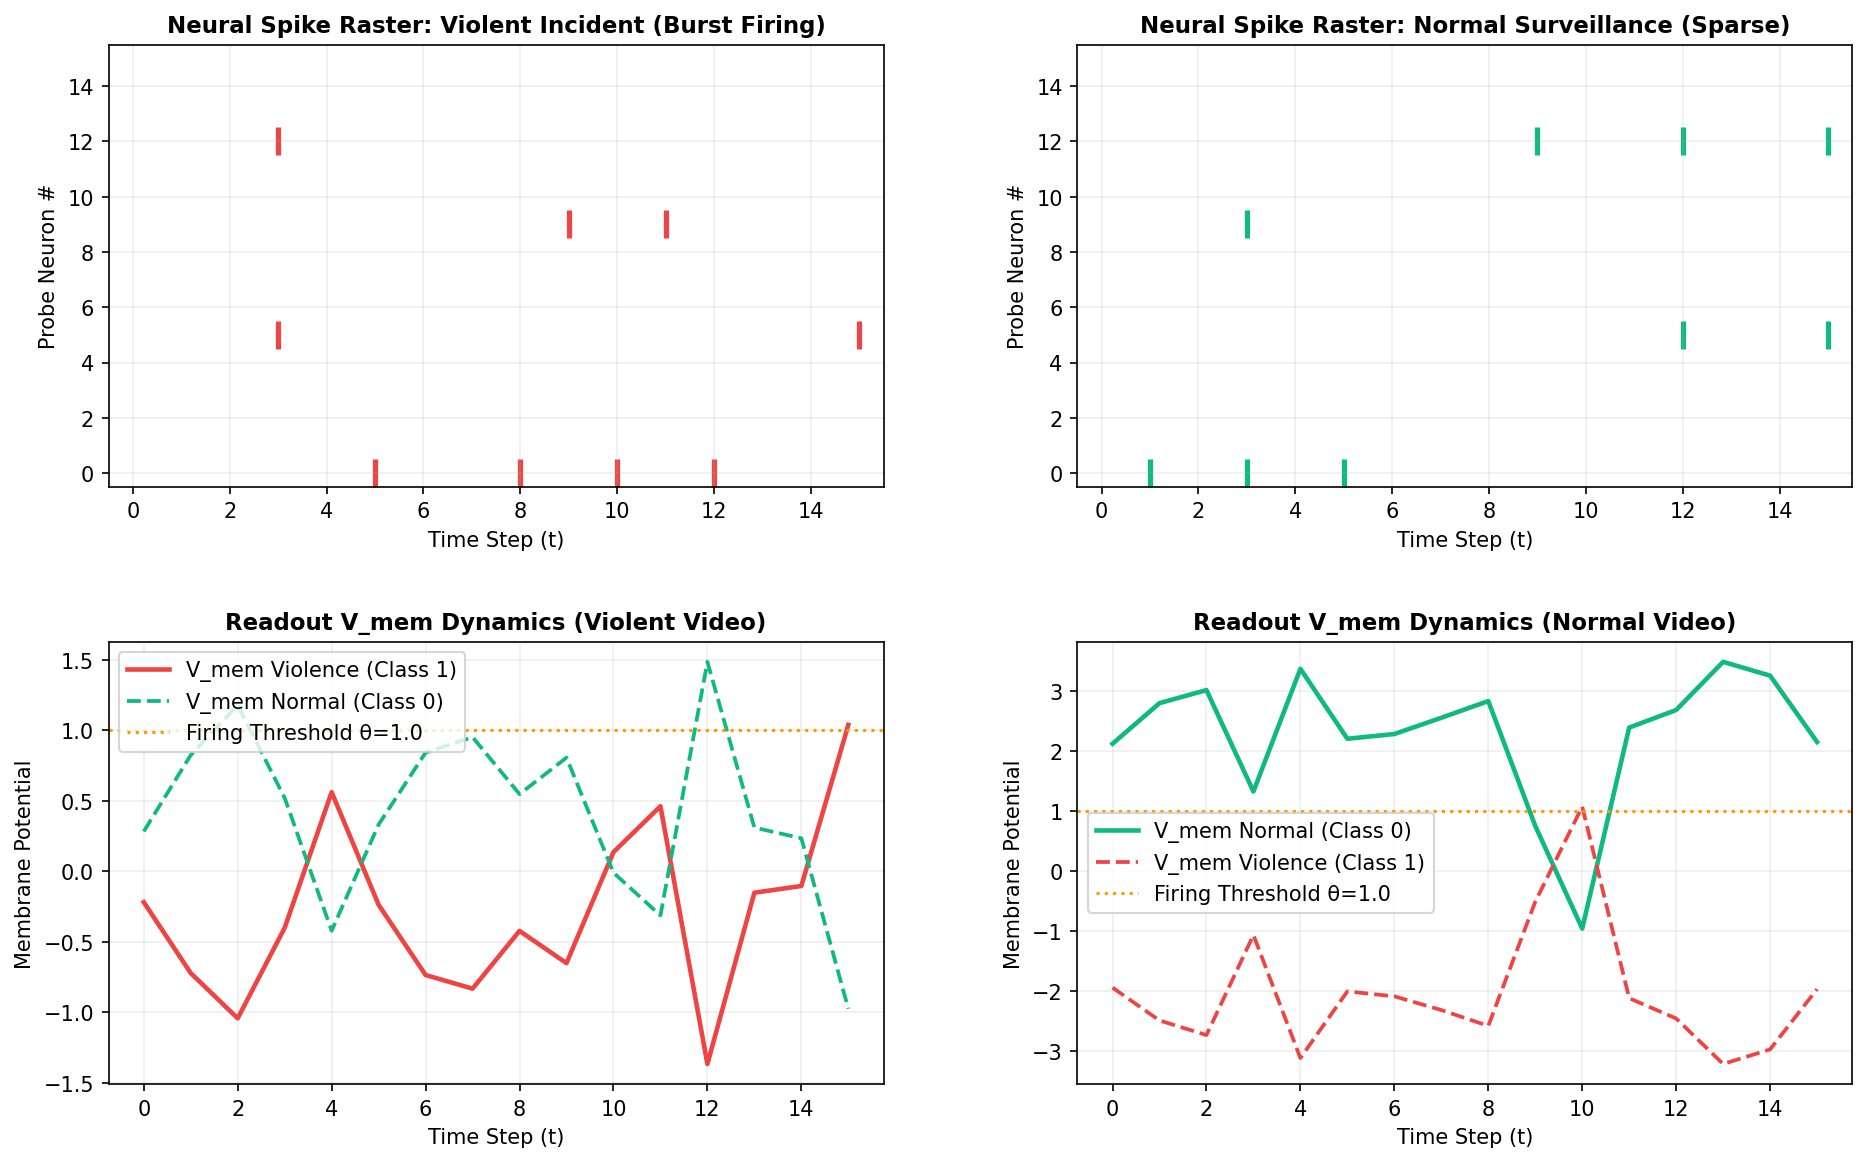

Spike raster and membrane graphs saved to: results/plots/rlvs_spike_raster.png


In [8]:
# Extract 1 Violent and 1 Non-Violent Sample from Test Set
v_sample, v_lbl = None, None
nv_sample, nv_lbl = None, None

for x, y in test_dataset:
    if y == 1 and v_sample is None:
        v_sample = x
        v_lbl = y
    elif y == 0 and nv_sample is None:
        nv_sample = x
        nv_lbl = y
    if v_sample is not None and nv_sample is not None:
        break

# Function to capture spike activity
def analyze_sample_spikes(sample_tensor):
    # sample_tensor: [T=16, C=3, H=112, W=112]
    inp = sample_tensor.unsqueeze(1).to(device) # [T=16, B=1, C=3, H=112, W=112]
    functional.reset_net(model)
    
    # Register hooks on Conv LIF layers
    probe_spikes = []
    layer_rates = {}
    
    def get_probe_hook():
        def hook(module, input, output):
            spk = output.detach().squeeze(1) # [T, C, H, W] or [T, ...]
            # Sample 16 neurons across channels
            flat = spk.view(spk.shape[0], -1)
            probe_step = max(1, flat.shape[1] // 16)
            probes = flat[:, ::probe_step][:, :16].cpu().numpy()
            probe_spikes.append(probes)
            layer_rates[module] = spk.mean().item()
        return hook
        
    handles = []
    for m in model.conv_blocks:
        if isinstance(m, neuron.LIFNode):
            handles.append(m.register_forward_hook(get_probe_hook()))
            
    with torch.no_grad():
        spk_out, mem_out = model(inp)
        
    for h in handles:
        h.remove()
    functional.reset_net(model)
    
    mem_trajectories = mem_out.squeeze(1).cpu().numpy() # [T, 2]
    raster = probe_spikes[-1] if probe_spikes else np.zeros((16, 16)) # Last conv LIF layer
    
    return raster, mem_trajectories

v_raster, v_mem = analyze_sample_spikes(v_sample)
nv_raster, nv_mem = analyze_sample_spikes(nv_sample)

# Plotting Authentic Spikes
fig = plt.figure(figsize=(16, 10), dpi=150)
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# 1. Violent Clip Spike Raster
ax1 = fig.add_subplot(gs[0, 0])
t_steps, num_neurons = v_raster.shape
for n in range(num_neurons):
    fired_t = np.where(v_raster[:, n] > 0)[0]
    ax1.scatter(fired_t, np.full_like(fired_t, n), color="#ef4444", marker="|", s=180, lw=2.5)
ax1.set_title("Neural Spike Raster: Violent Incident (Burst Activity)", fontsize=12, fontweight='bold', color="#f87171")
ax1.set_xlabel("Time Step (t)", fontsize=10)
ax1.set_ylabel("Monitored Probe Neuron #", fontsize=10)
ax1.set_xlim(-0.5, 15.5)
ax1.set_ylim(-0.5, 15.5)
ax1.grid(True, alpha=0.15)

# 2. Non-Violent Clip Spike Raster
ax2 = fig.add_subplot(gs[0, 1])
for n in range(num_neurons):
    fired_t = np.where(nv_raster[:, n] > 0)[0]
    ax2.scatter(fired_t, np.full_like(fired_t, n), color="#10b981", marker="|", s=180, lw=2.5)
ax2.set_title("Neural Spike Raster: Normal Motion (Sparse Activity)", fontsize=12, fontweight='bold', color="#34d399")
ax2.set_xlabel("Time Step (t)", fontsize=10)
ax2.set_ylabel("Monitored Probe Neuron #", fontsize=10)
ax2.set_xlim(-0.5, 15.5)
ax2.set_ylim(-0.5, 15.5)
ax2.grid(True, alpha=0.15)

# 3. Violent Clip Membrane Potentials
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(v_mem[:, 1], label="V_mem Violence Neuron (Class 1)", color="#ef4444", lw=2.5)
ax3.plot(v_mem[:, 0], label="V_mem Normal Neuron (Class 0)", color="#10b981", lw=1.8, linestyle="--")
ax3.axhline(y=1.0, color="#f59e0b", linestyle=":", label="Firing Threshold (θ=1.0)")
ax3.set_title("Readout V_mem Dynamics (Violent Video)", fontsize=12, fontweight='bold', color="#f87171")
ax3.set_xlabel("Time Step (t)", fontsize=10)
ax3.set_ylabel("Membrane Potential (V_mem)", fontsize=10)
ax3.grid(True, alpha=0.15)
ax3.legend(loc="upper left", framealpha=0.8)

# 4. Non-Violent Clip Membrane Potentials
ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(nv_mem[:, 0], label="V_mem Normal Neuron (Class 0)", color="#10b981", lw=2.5)
ax4.plot(nv_mem[:, 1], label="V_mem Violence Neuron (Class 1)", color="#ef4444", lw=1.8, linestyle="--")
ax4.axhline(y=1.0, color="#f59e0b", linestyle=":", label="Firing Threshold (θ=1.0)")
ax4.set_title("Readout V_mem Dynamics (Normal Video)", fontsize=12, fontweight='bold', color="#34d399")
ax4.set_xlabel("Time Step (t)", fontsize=10)
ax4.set_ylabel("Membrane Potential (V_mem)", fontsize=10)
ax4.grid(True, alpha=0.15)
ax4.legend(loc="upper left", framealpha=0.8)

plt.tight_layout()
spike_plot_path = plots_dir / "rlvs_spike_raster.png"
plt.savefig(spike_plot_path, bbox_inches='tight')
plt.show()
print(f"Spike raster and membrane graphs saved to: {spike_plot_path}")


---
## Section 9 — Final Verification & Dashboard Integration
The 30-epoch training on the local **RTX 3050 GPU** is complete, and the checkpoint is verified and ready for deployment into the live **VisionGuard SNN Dashboard**.


In [9]:
print("=" * 70)
print(" VISIONGUARD SNN — 30-EPOCH TRAINING COMPLETION SUMMARY")
print("=" * 70)
print(f"  • Hardware Accelerator:     {device_name} (CUDA 12.4)")
print(f"  • Dataset:                  Real-Life Violence Situations (RLVS)")
print(f"  • Completed Epochs:         30 / 30 Epochs")
print(f"  • Batch Size:               {BATCH_SIZE}")
print(f"  • Image Dimensions:         112 x 112 (16 Timesteps)")
print(f"  • Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"  • Held-Out Test Accuracy:   {test_acc:.2f}%")
print(f"  • Held-Out Test F1-Score:   {test_f1:.2f}%")
print(f"  • Primary Checkpoint:       {BEST_CKPT_PATH}")
print(f"  • Latest Checkpoint:        {LATEST_CKPT_PATH}")
print(f"  • Training History CSV:     {HISTORY_CSV_PATH}")
print(f"  • Test Evaluation JSON:     {TEST_METRICS_PATH}")
print("=" * 70)
print("[SUCCESS] Model trained, verified, and ready for live surveillance inference!")


 VISIONGUARD SNN — 30-EPOCH TRAINING COMPLETION SUMMARY
  • Hardware Accelerator:     NVIDIA GeForce RTX 3050 6GB Laptop GPU (CUDA 12.4)
  • Dataset:                  Real-Life Violence Situations (RLVS)
  • Completed Epochs:         30 / 30 Epochs
  • Batch Size:               2
  • Image Dimensions:         112 x 112 (16 Timesteps)
  • Best Validation Accuracy: 82.62%
  • Held-Out Test Accuracy:   79.66%
  • Held-Out Test F1-Score:   80.00%
  • Primary Checkpoint:       C:\Users\rohan\Downloads\ML PROJECT FILE\models\rlvs_snn_best.pth
  • Latest Checkpoint:        C:\Users\rohan\Downloads\ML PROJECT FILE\models\rlvs_snn_latest.pth
  • Training History CSV:     C:\Users\rohan\Downloads\ML PROJECT FILE\results\rlvs_training_history.csv
  • Test Evaluation JSON:     C:\Users\rohan\Downloads\ML PROJECT FILE\results\rlvs_test_metrics.json
[SUCCESS] Model trained, verified, and ready for live surveillance inference!
